# Évaluation de l'élève : la section 8, sur un ordinateur ordinaire

Ce notebook reproduit **la section 8 du notebook de distillation** (l'évaluation finale sur le jeu de test) **sans GPU ni PyTorch**. Il réutilise les fichiers produits sur le serveur :

| Fichier | Contenu | Sert aux niveaux |
|---|---|---|
| `models/eleve_emotions/predictions_val_test.npz` | les 5 scores de l'élève sur la validation et le test, **avec les identifiants** | 1 et 4 |
| `models/eleve_emotions/eleve.onnx` + `tokenizer/` | le modèle, pour recalculer les 28 émotions de l'élève | 2 et 3 |
| `models/eleve_emotions/couche_factorielle.npz` | les tables de rangs et les poids de la thèse | 2, 3 et contrôles |
| `../data/…` | les textes, les 28 probabilités de l'enseignant, les Z-scores, les résultats de l'EFA | tous |

**Plan**

| Partie | Contenu | Durée |
|---|---|---|
| 1 | Configuration | — |
| 2 | Chargement et contrôles | 1 min |
| 3 | La couche factorielle | quelques secondes |
| 4 | Les 28 émotions de l'élève, recalculées avec ONNX | **30 à 60 min la première fois**, puis instantané (cache) |
| 5 | Niveau 1 : les 5 dimensions | — |
| 6 | Niveau 2 : les 28 émotions | — |
| 7 | Niveau 3 : la structure factorielle | — |
| 8 | Niveau 4 : la dimension dominante, le tableau croisé et l'étiquette à deux niveaux | — |

**Prérequis**, à lancer depuis le dossier `notebooks/` :
```bash
uv run --no-project --with jupyterlab --with onnxruntime --with transformers --with sentencepiece \
    --with protobuf --with pandas --with scikit-learn --with matplotlib --with tqdm jupyter lab
```

**Important** : le fichier de prédictions doit contenir les identifiants des verbatims (`id_val`, `id_test`). S'ils manquent, la partie 2 s'arrête avec un message : il faut d'abord les ajouter sur le serveur (voir la cellule fournie à part), puis recopier le fichier.

## 1. Configuration

- **`N_TEST_ONNX`** : nombre de verbatims du test sur lesquels on recalcule les 28 émotions (niveaux 2 et 3). `None` les prend tous (16 096, 30 à 60 minutes). Avec 4 000, c'est environ 4 fois plus court, et les résultats des niveaux 2 et 3 restent très proches.
- **`N_THREADS`** : le nombre de cœurs **performants** du processeur. Sur votre Mac, 4 était le plus rapide.

In [28]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import onnxruntime as ort
from sklearn.metrics import cohen_kappa_score
from tqdm.auto import tqdm
from transformers import AutoTokenizer
from IPython.display import display

DATA_DIR   = Path("../data")
MODELE_DIR = Path("models/eleve_emotions")
SORTIES    = Path("resultats_section8")
SORTIES.mkdir(exist_ok=True)

N_TEST_ONNX = None    # None = tout le test ; par exemple 4000 pour aller plus vite
N_THREADS   = 4
SEED        = 42
ID          = "id_experience"

with open(MODELE_DIR / "config_production.json", encoding="utf-8") as f:
    CONFIG = json.load(f)
EMOTIONS, DIMENSIONS, MAX_LEN = CONFIG["emotions"], CONFIG["dimensions"], CONFIG["max_len"]
FACTEURS = CONFIG.get("facteurs", {"MR1": "satisfaction", "MR2": "perplexite", "MR3": "desillusion",
                                   "MR4": "contestation", "MR5": "detresse"})
print(len(EMOTIONS), "émotions |", ", ".join(DIMENSIONS), "| MAX_LEN =", MAX_LEN)

28 émotions | satisfaction, perplexite, desillusion, contestation, detresse | MAX_LEN = 512


## 2. Chargement

On lit les fichiers de données et on normalise l'identifiant (texte, sans espaces), pour que les jointures fonctionnent quel que soit le format d'origine.

Le texte de chaque verbatim est reconstruit comme pendant l'entraînement : `Titre`, saut de ligne, `Description`.

In [29]:
def lire(path, sep):
    df = pd.read_csv(path, sep=sep, encoding="utf-8-sig")
    df = df.rename(columns={c: ID for c in df.columns if c.strip().lower() in {"id_experience", "id expérience"}})
    ids = df[ID]
    if pd.api.types.is_float_dtype(ids):
        ids = ids.astype("Int64")
    df[ID] = ids.astype(str).str.strip()
    return df.drop_duplicates(ID).set_index(ID)


emotions = lire(DATA_DIR / "xp_emotions_28.csv", ",")
zscores  = lire(DATA_DIR / "Zscores_dimensions.csv", ",")
verbatim = lire(DATA_DIR / "verbatim_2026_07_31.csv", ";")
verbatim["texte"] = (verbatim["Titre"].fillna("").astype(str).str.strip() + "\n\n"
                     + verbatim["Description"].fillna("").astype(str).str.strip()).str.strip()
print(f"émotions {len(emotions)} | Z-scores {len(zscores)} | verbatims {len(verbatim)}")

émotions 160962 | Z-scores 160962 | verbatims 160962


### Les jeux de validation et de test du serveur

On reprend **exactement** les verbatims utilisés sur le serveur, grâce aux identifiants enregistrés avec les prédictions. Recréer le découpage ici ne garantirait pas le même résultat : le tri par date n'ordonne pas toujours les ex-aequo de la même façon d'une machine à l'autre.

**Contrôle** : la corrélation entre les scores de l'élève et ceux de la thèse doit valoir environ 0,96 à 0,98. Une valeur proche de 0 signalerait un décalage entre identifiants et scores.

In [30]:
p = np.load(MODELE_DIR / "predictions_val_test.npz", allow_pickle=True)
if "id_test" not in p.files:
    raise KeyError("Le fichier de prédictions ne contient pas les identifiants (id_val, id_test). "
                   "Ajoutez-les sur le serveur avec la cellule prévue, puis recopiez le fichier.")

jeux = {}
for nom, cle_f, cle_id in [("validation", "F_val_eleve", "id_val"), ("test", "F_test_eleve", "id_test")]:
    ids = pd.Index(p[cle_id].astype(str), name=ID)
    jeux[nom] = {"ids": ids, "F_eleve": p[cle_f].astype(np.float64),
                 "F_these": zscores.loc[ids, DIMENSIONS].to_numpy(np.float64)}
    r = [np.corrcoef(jeux[nom]["F_eleve"][:, k], jeux[nom]["F_these"][:, k])[0, 1] for k in range(len(DIMENSIONS))]
    print(f"{nom:<11} {len(ids):>6} verbatims | corrélation élève / thèse : " + ", ".join(f"{v:.3f}" for v in r))
    assert min(r) > 0.9, "Scores de l'élève et de la thèse non alignés."

test_ids = jeux["test"]["ids"]
dates = pd.to_datetime(emotions.loc[test_ids, "date_publication"], errors="coerce")
print(f"Test : avis publiés du {dates.min():%d/%m/%Y} au {dates.max():%d/%m/%Y}")

validation   16096 verbatims | corrélation élève / thèse : 0.975, 0.967, 0.971, 0.975, 0.958
test         16096 verbatims | corrélation élève / thèse : 0.976, 0.968, 0.972, 0.976, 0.962
Test : avis publiés du 13/03/2026 au 31/07/2026


## 3. La couche factorielle de la thèse

Elle transforme les 28 émotions en 5 scores, en quatre temps : rang de chaque probabilité dans le corpus de la thèse, standardisation des rangs, poids de Bartlett, re-standardisation. Les tables de rangs et les poids finaux sont lus dans `couche_factorielle.npz`, tels qu'ils ont été figés sur le serveur.

Les poids de Bartlett $W$ sont recalculés à partir des fichiers de l'EFA (`pattern_matrix.csv`, `structure_finale.csv`). Ils ne servent qu'à l'affichage du niveau 2 (quelle émotion pèse le plus dans quelle dimension).

**Contrôle** : appliquée aux probabilités de l'enseignant, la couche doit redonner vos Z-scores, avec un écart maximal de l'ordre de 0,00001.

In [31]:
EPS = 1e-6
couche = np.load(MODELE_DIR / "couche_factorielle.npz")
TABLES = [(couche[f"x_{j}"], couche[f"y_{j}"]) for j in range(len(EMOTIONS))]
W_FINAL, C_FINAL = couche["W_final"], couche["c_final"]


def logit(p):
    p = np.clip(np.asarray(p, dtype=np.float64), EPS, 1 - EPS)
    return np.log(p / (1 - p))


def rangs_standardises(logits):
    logits = np.asarray(logits, dtype=np.float64)
    return np.column_stack([np.interp(logits[:, j], x, y) for j, (x, y) in enumerate(TABLES)])


def couche_factorielle(logits):
    return rangs_standardises(logits) @ W_FINAL + C_FINAL


# Poids de Bartlett (affichage du niveau 2)
pattern = pd.read_csv(DATA_DIR / "pattern_matrix.csv", index_col=0, encoding="utf-8-sig").rename(columns=FACTEURS)
unicites = pd.read_csv(DATA_DIR / "structure_finale.csv", encoding="utf-8-sig").set_index("Item")["u2"]
L = pattern.loc[EMOTIONS, DIMENSIONS].to_numpy(np.float64)
psi_inv = 1 / unicites.loc[EMOTIONS].to_numpy(np.float64)
W = (psi_inv[:, None] * L) @ np.linalg.inv(L.T @ (psi_inv[:, None] * L))

# Contrôle sur le test
L_test_ens = logit(emotions.loc[test_ids, EMOTIONS])
ecart = np.abs(couche_factorielle(L_test_ens) - jeux["test"]["F_these"])
print(f"Couche appliquée à l'enseignant vs Z-scores : écart max {ecart.max():.6f}")
assert ecart.max() < 1e-3

Couche appliquée à l'enseignant vs Z-scores : écart max 0.000008


## 4. Les 28 émotions de l'élève (pour les niveaux 2 et 3)

Le fichier de prédictions ne contient que les 5 scores. Pour les niveaux 2 et 3, il faut les 28 émotions : on les recalcule avec `eleve.onnx`, qui donne les mêmes résultats que le modèle du serveur.

- Les textes sont **triés par longueur** avant d'être regroupés par paquets de 32, ce qui évite de compléter un texte court jusqu'à la longueur d'un texte long. Les résultats sont ensuite remis dans l'ordre d'origine.
- Le résultat est **mis en cache** dans `resultats_section8/logits_test.npz` : les fois suivantes, cette cellule est instantanée.

**Contrôle** : les 5 scores recalculés ici doivent être quasiment identiques à ceux du serveur. De petits écarts (de l'ordre de 0,01) sont normaux : le serveur calculait en précision réduite (bfloat16) sur GPU, ONNX calcule en précision complète.

In [32]:
cache = SORTIES / "logits_test.npz"
ids_onnx = test_ids if N_TEST_ONNX is None else test_ids[np.random.default_rng(SEED).permutation(len(test_ids))[:N_TEST_ONNX]]

if cache.exists() and set(np.load(cache, allow_pickle=True)["ids"].astype(str)) >= set(ids_onnx):
    c = np.load(cache, allow_pickle=True)
    L_eleve = pd.DataFrame(c["logits"], index=pd.Index(c["ids"].astype(str), name=ID)).loc[ids_onnx].to_numpy()
    print(f"Logits lus dans le cache ({len(ids_onnx)} verbatims)")
else:
    tokenizer = AutoTokenizer.from_pretrained(MODELE_DIR / "tokenizer")
    so = ort.SessionOptions()
    so.intra_op_num_threads = N_THREADS
    so.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
    session = ort.InferenceSession(str(MODELE_DIR / "eleve.onnx"), so, providers=["CPUExecutionProvider"])

    textes = verbatim.loc[ids_onnx, "texte"].tolist()
    ordre = np.argsort([len(t) for t in textes])
    L_eleve = np.zeros((len(textes), len(EMOTIONS)), dtype=np.float32)
    debut = time.time()
    for i in tqdm(range(0, len(textes), 32), desc="ONNX"):
        idx = ordre[i:i + 32]
        enc = tokenizer([textes[j] for j in idx], truncation=True, max_length=MAX_LEN, padding=True, return_tensors="np")
        L_eleve[idx] = session.run(None, {"input_ids": enc["input_ids"].astype(np.int64),
                                          "attention_mask": enc["attention_mask"].astype(np.int64)})[0]
    print(f"{len(textes)} verbatims en {(time.time() - debut) / 60:.0f} min")
    np.savez(cache, logits=L_eleve, ids=np.asarray(ids_onnx, dtype=str))

# Contrôle par rapport aux scores du serveur
pos = test_ids.get_indexer(ids_onnx)
F_onnx = couche_factorielle(L_eleve)
F_serveur = jeux["test"]["F_eleve"][pos]
print(f"5 scores ONNX vs serveur : écart moyen {np.abs(F_onnx - F_serveur).mean():.4f}, "
      f"corrélation minimale {min(np.corrcoef(F_onnx[:, k], F_serveur[:, k])[0, 1] for k in range(5)):.4f}")

Logits lus dans le cache (16096 verbatims)
5 scores ONNX vs serveur : écart moyen 0.0036, corrélation minimale 1.0000


## 5. Niveau 1 : les 5 dimensions

On compare les scores de l'élève à vos Z-scores, verbatim par verbatim. Les scores de l'élève utilisés ici sont ceux du serveur, pour reproduire exactement la section 8.

- **r** : corrélation de Pearson. 1 = l'élève classe et espace les verbatims exactement comme la thèse.
- **MAE** : écart absolu moyen, en unités de Z-score (écart-type 1, étendue d'environ −2 à +2).
- **à ±0,10 / à ±0,25** : part des verbatims dont le score de l'élève tombe à moins de 0,10 (ou 0,25) de la thèse.

,r,MAE,"à ±0,10","à ±0,25"
satisfaction,0.976,0.192,41%,72%
perplexite,0.968,0.194,36%,72%
desillusion,0.972,0.191,37%,73%
contestation,0.976,0.176,38%,76%
detresse,0.962,0.205,38%,70%


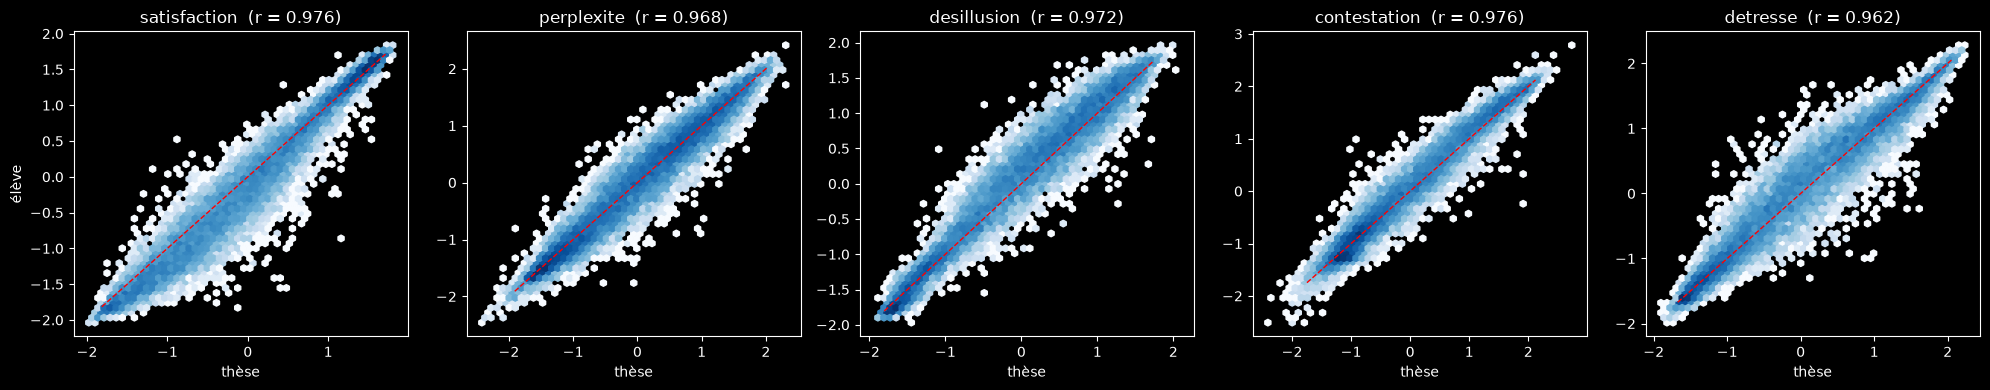

In [33]:
def correlations(a, b):
    a = a - a.mean(0)
    b = b - b.mean(0)
    return (a * b).sum(0) / np.sqrt((a ** 2).sum(0) * (b ** 2).sum(0))


Fe, Ft = jeux["test"]["F_eleve"], jeux["test"]["F_these"]
ecarts = np.abs(Fe - Ft)
res_dim = pd.DataFrame({"r": correlations(Fe, Ft), "MAE": ecarts.mean(0),
                        "à ±0,10": (ecarts <= 0.10).mean(0), "à ±0,25": (ecarts <= 0.25).mean(0)}, index=DIMENSIONS)
display(res_dim.style.format({"r": "{:.3f}", "MAE": "{:.3f}", "à ±0,10": "{:.0%}", "à ±0,25": "{:.0%}"}))

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for k, (ax, d) in enumerate(zip(axes, DIMENSIONS)):
    ax.hexbin(Ft[:, k], Fe[:, k], gridsize=50, bins="log", cmap="Blues")
    lo, hi = np.percentile(Ft[:, k], [0.5, 99.5])
    ax.plot([lo, hi], [lo, hi], "r--", lw=1)
    ax.set_title(f"{d}  (r = {res_dim.loc[d, 'r']:.3f})"); ax.set_xlabel("thèse")
axes[0].set_ylabel("élève")
plt.tight_layout(); plt.show()

Chaque point est un verbatim : plus les points se serrent autour de la diagonale rouge, plus l'imitation est fidèle. Regardez surtout les extrémités : si les points s'aplatissaient à l'horizontale aux bords, l'élève écraserait les cas extrêmes.

## 6. Niveau 2 : les 28 émotions

Pour chaque émotion, on compare l'élève et l'enseignant sur les **rangs standardisés**, c'est-à-dire la grandeur que la thèse utilise. Une émotion mal reproduite n'est grave que si elle pèse lourd dans une dimension : le tableau indique donc aussi son plus gros poids de Bartlett et la dimension concernée.

In [34]:
R_eleve = rangs_standardises(L_eleve)
R_ens = rangs_standardises(L_test_ens[pos])
P_eleve = 1 / (1 + np.exp(-L_eleve))
res_emo = pd.DataFrame({
    "r (rangs)": correlations(R_eleve, R_ens),
    "écart moyen de proba": np.abs(P_eleve - emotions.loc[ids_onnx, EMOTIONS].to_numpy()).mean(0),
    "poids max |W|": np.abs(W).max(1),
    "dimension du plus gros poids": [DIMENSIONS[k] for k in np.abs(W).argmax(1)],
}, index=EMOTIONS).sort_values("r (rangs)")
display(res_emo.round(3))

,r (rangs),écart moyen de proba,poids max |W|,dimension du plus gros poids
Surprise,0.929,0.045,0.137,perplexite
Détermination,0.934,0.043,0.043,satisfaction
Impuissance,0.942,0.085,0.045,desillusion
Anxiété,0.943,0.029,0.291,detresse
Renoncement,0.945,0.031,0.091,desillusion
Résignation,0.948,0.077,0.277,desillusion
Confiance,0.949,0.039,0.063,satisfaction
Enthousiasme,0.951,0.028,0.078,satisfaction
Doute,0.951,0.068,0.163,perplexite
Regret,0.953,0.083,0.105,desillusion


## 7. Niveau 3 : la structure factorielle

On vérifie que l'élève respecte le **lien entre chaque émotion et chaque dimension**. Pour l'enseignant puis pour l'élève, on calcule la corrélation entre chacune des 28 émotions (en rangs) et chacune des 5 dimensions, puis on compare les deux tableaux avec le **coefficient de congruence de Tucker** (φ). φ ≥ 0,95 : les deux structures sont considérées comme identiques.

In [35]:
def matrice_structure(R, F):
    Rc = (R - R.mean(0)) / R.std(0)
    Fc = (F - F.mean(0)) / F.std(0)
    return Rc.T @ Fc / len(R)


S_ens = matrice_structure(R_ens, Ft[pos])
S_eleve = matrice_structure(R_eleve, couche_factorielle(L_eleve))
phi = (S_ens * S_eleve).sum(0) / np.sqrt((S_ens ** 2).sum(0) * (S_eleve ** 2).sum(0))
res_dim["φ de Tucker"] = phi
display(pd.Series(phi, index=DIMENSIONS, name="φ de Tucker").round(4).to_frame())

,φ de Tucker
satisfaction,0.9999
perplexite,0.9991
desillusion,0.9998
contestation,0.9993
detresse,0.9995


## 8. Niveau 4 : la dimension dominante

Pour chaque verbatim, la **dimension dominante** est celle qui a le score le plus élevé (la plus au-dessus de la moyenne du corpus de la thèse).

- **Accord** : part des verbatims où l'élève et la thèse désignent la même dimension.
- **κ de Cohen** : le même accord, corrigé de ce qu'on obtiendrait par hasard. Au-dessus de 0,8, l'accord est très bon.

In [36]:
noms = np.array(DIMENSIONS)
for nom, j in jeux.items():
    de, dt = j["F_eleve"].argmax(1), j["F_these"].argmax(1)
    print(f"{nom:<11} accord {(de == dt).mean():.1%} | κ de Cohen {cohen_kappa_score(dt, de):.3f}")

validation  accord 86.8% | κ de Cohen 0.833
test        accord 87.4% | κ de Cohen 0.840


### Le tableau croisé, avec pourcentages

Lignes : dimension dominante selon la **thèse**. Colonnes : selon l'**élève**. Chaque case donne l'effectif et le pourcentage **en ligne** (parmi les verbatims que la thèse classe dans une dimension, la part que l'élève classe dans chacune).

La ligne **« élève d'accord »** donne la diagonale en pourcentage **en colonne** : quand l'élève attribue une dimension, la part des cas où c'est aussi celle de la thèse.

élève,satisfaction,perplexite,desillusion,contestation,detresse,total thèse
thèse,,,,,,
satisfaction,4442 (93.0 %),145 (3.0 %),67 (1.4 %),32 (0.7 %),90 (1.9 %),4776
perplexite,81 (2.3 %),2854 (82.4 %),248 (7.2 %),142 (4.1 %),139 (4.0 %),3464
desillusion,9 (0.4 %),69 (2.8 %),2153 (86.3 %),174 (7.0 %),91 (3.6 %),2496
contestation,19 (0.7 %),51 (1.8 %),104 (3.6 %),2667 (92.4 %),45 (1.6 %),2886
detresse,35 (1.4 %),122 (4.9 %),252 (10.2 %),114 (4.6 %),1951 (78.9 %),2474
élève d'accord,96.9%,88.1%,76.2%,85.2%,84.2%,
total élève,4586,3241,2824,3129,2316,16096


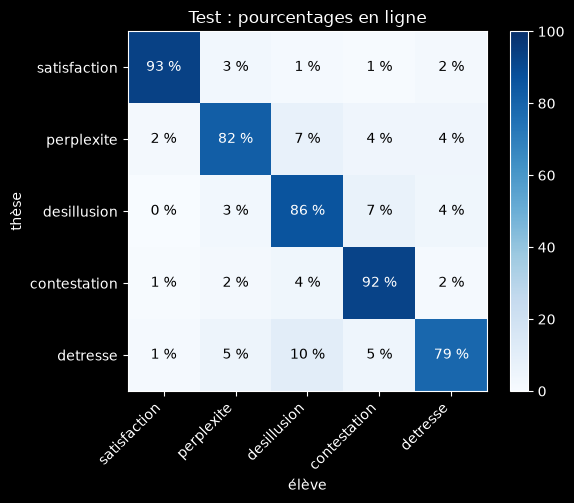

In [37]:
def tableau_croise(Fe, Ft):
    ct = pd.crosstab(pd.Series(noms[Ft.argmax(1)], name="thèse"),
                     pd.Series(noms[Fe.argmax(1)], name="élève")).reindex(index=DIMENSIONS, columns=DIMENSIONS, fill_value=0)
    lignes = ct.div(ct.sum(axis=1), axis=0)
    affichage = ct.astype(str) + " (" + (100 * lignes).round(1).astype(str) + " %)"
    affichage["total thèse"] = ct.sum(axis=1).astype(str)
    affichage.loc["élève d'accord"] = [f"{v:.1%}" for v in np.diag(ct) / ct.sum(axis=0)] + [""]
    affichage.loc["total élève"] = [str(v) for v in ct.sum(axis=0)] + [str(ct.values.sum())]
    return lignes, affichage


lignes, affichage = tableau_croise(jeux["test"]["F_eleve"], jeux["test"]["F_these"])
display(affichage)
affichage.to_csv(SORTIES / "tableau_croise_test.csv")

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(100 * lignes.to_numpy(), cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(5), DIMENSIONS, rotation=45, ha="right"); ax.set_yticks(range(5), DIMENSIONS)
for i in range(5):
    for k in range(5):
        v = 100 * lignes.iloc[i, k]
        ax.text(k, i, f"{v:.0f} %", ha="center", va="center", color="white" if v > 50 else "black")
ax.set_xlabel("élève"); ax.set_ylabel("thèse"); ax.set_title("Test : pourcentages en ligne")
plt.colorbar(im, ax=ax); plt.tight_layout(); plt.show()

### Où se situent les désaccords

**(a)** On classe les verbatims selon l'écart, **dans la thèse**, entre la 1re et la 2e dimension. Si les désaccords se concentrent dans les petits écarts, l'élève se trompe surtout là où la thèse elle-même hésite.

**(b)** Part des verbatims pour lesquels la dominante de la thèse figure parmi les deux premières dimensions de l'élève.

In [38]:
def top2(F):
    ordre = np.argsort(-F, axis=1)
    l = np.arange(len(F))
    return ordre[:, 0], ordre[:, 1], F[l, ordre[:, 0]] - F[l, ordre[:, 1]]


e1, e2, _ = top2(jeux["test"]["F_eleve"])
t1, _, ecart_these = top2(jeux["test"]["F_these"])
desaccord = e1 != t1
lignes_diag = []
for a, b in [(0, .1), (.1, .25), (.25, .5), (.5, 1), (1, np.inf)]:
    sel = (ecart_these >= a) & (ecart_these < b)
    lignes_diag.append({"écart dans la thèse": f"{a} à {b}", "part des verbatims": sel.mean(),
                        "accord": 1 - desaccord[sel].mean(), "part des désaccords": desaccord[sel].sum() / desaccord.sum()})
display(pd.DataFrame(lignes_diag).set_index("écart dans la thèse").style.format("{:.1%}"))
print(f"(b) Dominante de la thèse parmi les deux premières de l'élève : {((t1 == e1) | (t1 == e2)).mean():.1%}")

,part des verbatims,accord,part des désaccords
écart dans la thèse,,,
0 à 0.1,9.2%,51.8%,35.3%
0.1 à 0.25,13.0%,66.5%,34.5%
0.25 à 0.5,17.3%,83.6%,22.4%
0.5 à 1,22.5%,96.0%,7.0%
1 à inf,38.1%,99.8%,0.7%


(b) Dominante de la thèse parmi les deux premières de l'élève : 97.5%


### L'étiquette à deux niveaux : choisir le seuil

- **nette** : une seule dimension, quand l'écart entre les deux premières dimensions **de l'élève** est d'au moins `seuil` ;
- **mixte** : les deux premières dimensions, quand l'écart est inférieur à `seuil`.

L'écart est calculé sur l'élève, seule information disponible en production. Plus le seuil est élevé, plus il y a de mixtes, et plus les étiquettes nettes sont fiables.

**Colonnes** : **n mixte / part mixte** (combien de mixtes) ; **mixte : même paire** (la thèse a les deux mêmes dimensions en tête, critère strict) ; **mixte : dominante thèse dans la paire** (critère souple) ; **nettes : même dominante** ; **total (strict)** et **total (souple)** sur tous les verbatims. Le total souple augmente mécaniquement avec la part de mixtes : il ne suffit pas à choisir le seuil.

Le seuil se choisit sur la **validation** ; le test sert à confirmer.

In [39]:
SEUILS = np.round(np.linspace(1, 0.01, 100), 2)      # de 1,00 à 0,01 par pas de 0,01


def tableau_seuils(Fe, Ft, seuils):
    e1, e2, ecart = top2(Fe)
    t1, t2, _ = top2(Ft)
    meme_dominante = e1 == t1
    meme_paire = ((e1 == t1) & (e2 == t2)) | ((e1 == t2) & (e2 == t1))
    dans_paire = (t1 == e1) | (t1 == e2)
    lignes = []
    for s in seuils:
        mixte = ecart < s
        lignes.append({
            "seuil": s, "n mixte": int(mixte.sum()), "part mixte": mixte.mean(),
            "mixte : même paire": meme_paire[mixte].mean() if mixte.any() else np.nan,
            "mixte : dominante thèse dans la paire": dans_paire[mixte].mean() if mixte.any() else np.nan,
            "nettes : même dominante": meme_dominante[~mixte].mean() if (~mixte).any() else np.nan,
            "total (strict)": np.where(mixte, meme_paire, meme_dominante).mean(),
            "total (souple)": np.where(mixte, dans_paire, meme_dominante).mean(),
        })
    return pd.DataFrame(lignes).set_index("seuil")


FORMATS = {c: "{:.1%}" for c in ["part mixte", "mixte : même paire", "mixte : dominante thèse dans la paire",
                                  "nettes : même dominante", "total (strict)", "total (souple)"]}
seuils_res = {nom: tableau_seuils(j["F_eleve"], j["F_these"], SEUILS) for nom, j in jeux.items()}
for nom, t in seuils_res.items():
    t.to_csv(SORTIES / f"seuils_{nom}.csv")
print("VALIDATION")
display(seuils_res["validation"].style.format(FORMATS))

VALIDATION


,n mixte,part mixte,mixte : même paire,mixte : dominante thèse dans la paire,nettes : même dominante,total (strict),total (souple)
seuil,,,,,,,
1.000000,10314,64.1%,77.4%,95.9%,99.7%,85.4%,97.3%
0.990000,10276,63.8%,77.4%,95.9%,99.7%,85.4%,97.3%
0.980000,10230,63.6%,77.4%,95.9%,99.6%,85.5%,97.2%
0.970000,10194,63.3%,77.4%,95.9%,99.6%,85.6%,97.2%
0.960000,10147,63.0%,77.4%,95.8%,99.6%,85.6%,97.2%
0.950000,10091,62.7%,77.5%,95.8%,99.6%,85.7%,97.2%
0.940000,10032,62.3%,77.5%,95.8%,99.6%,85.8%,97.2%
0.930000,9979,62.0%,77.4%,95.8%,99.6%,85.8%,97.2%
0.920000,9917,61.6%,77.4%,95.7%,99.6%,85.9%,97.2%


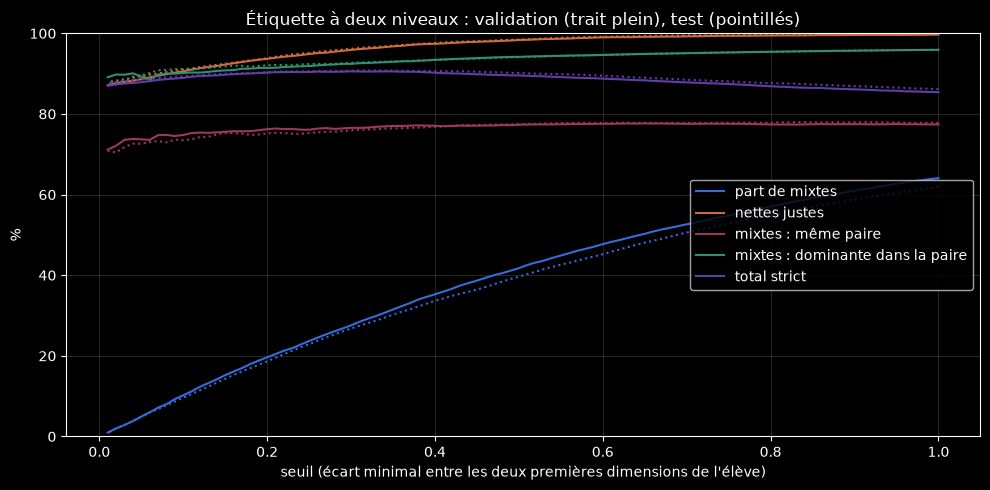

In [40]:
fig, ax = plt.subplots(figsize=(10, 5))
series = [("part mixte", "part de mixtes"), ("nettes : même dominante", "nettes justes"),
          ("mixte : même paire", "mixtes : même paire"),
          ("mixte : dominante thèse dans la paire", "mixtes : dominante dans la paire"), ("total (strict)", "total strict")]
couleurs = plt.rcParams["axes.prop_cycle"].by_key()["color"]
for (col, etiquette), c in zip(series, couleurs):
    ax.plot(SEUILS, 100 * seuils_res["validation"][col], color=c, label=etiquette)
    ax.plot(SEUILS, 100 * seuils_res["test"][col], color=c, ls=":")
ax.set_xlabel("seuil (écart minimal entre les deux premières dimensions de l'élève)")
ax.set_ylabel("%"); ax.set_ylim(0, 100); ax.grid(alpha=.3); ax.legend(loc="center right")
ax.set_title("Étiquette à deux niveaux : validation (trait plein), test (pointillés)")
plt.tight_layout(); plt.show()

### Appliquer le seuil retenu


Réglez `SEUIL` sur la valeur choisie à partir de la validation. La cellule donne le résultat **sur le test**. Pour les mixtes, la formulation recommandée est **« dominante incertaine : A ou B »**.

In [41]:
SEUIL = 0.30

ligne = seuils_res["test"].loc[SEUIL]
print(f"Seuil {SEUIL}, TEST :")
print(f"  {1 - ligne['part mixte']:.1%} d'étiquettes nettes, justes à {ligne['nettes : même dominante']:.1%}")
print(f"  {ligne['part mixte']:.1%} d'étiquettes mixtes : même paire {ligne['mixte : même paire']:.1%}, "
      f"dominante de la thèse dans la paire {ligne['mixte : dominante thèse dans la paire']:.1%}")
print(f"  total strict {ligne['total (strict)']:.1%} | total souple {ligne['total (souple)']:.1%}")

res_dim.to_csv(SORTIES / "niveau1_3_dimensions.csv")
res_emo.to_csv(SORTIES / "niveau2_emotions.csv")
print("\nTableaux enregistrés dans", SORTIES.resolve())

Seuil 0.3, TEST :
  73.2% d'étiquettes nettes, justes à 96.2%
  26.8% d'étiquettes mixtes : même paire 76.0%, dominante de la thèse dans la paire 92.7%
  total strict 90.8% | total souple 95.2%

Tableaux enregistrés dans /Users/blevy/Documents/DITP/Modele_emotions/notebooks/resultats_section8


## 9. Paire, triple, quadruplet : sur la totalité des verbatims

Jusqu'ici, un verbatim mixte annonçait toujours **deux** dimensions. Mais quand la deuxième dimension est proche de la première, la troisième l'est souvent aussi. Cette section généralise l'étiquette : on annonce **toutes les dimensions proches de la première**, qu'il y en ait 2, 3, 4 ou 5.

**Comment on compte les dimensions « dans le seuil ».** Pour chaque verbatim, on compte les dimensions dont le score **de l'élève** est à moins de `seuil` du score le plus élevé, celui-ci compris. Exemple, avec un seuil de 0,30 et des scores de 1,10, 1,02, 0,85, 0,40 et −0,50 : les trois premières sont à moins de 0,30 de 1,10, donc **3 dimensions dans le seuil**.
- 1 dimension : le verbatim est **net**, on annonce sa dimension dominante ;
- 2 à 5 dimensions : le verbatim est **mixte**, on annonce ce groupe de dimensions, et on vérifie que la thèse a les **mêmes** dimensions en tête, dans n'importe quel ordre.

L'écart est calculé sur les scores de l'élève, la seule information disponible en production.

**Sur la totalité des verbatims, et sur le test seul.** Le tableau est calculé sur les 161 000 verbatims, puis sur le test seul. Attention : 80 % des verbatims ont servi à l'entraînement, et l'élève a appris à imiter la thèse précisément sur ceux-là. Sur la totalité, les **parts** (combien de verbatims ont 2, 3, 4 ou 5 dimensions proches) ont tout leur sens, mais les **taux d'accord** sont un peu optimistes. Le tableau du test donne la mesure honnête pour de nouveaux avis.

### Les scores de l'élève sur tous les verbatims

Il faut d'abord les 5 scores de l'élève pour les 161 000 verbatims. Deux possibilités :

**1. Sur le serveur (recommandé, 10 à 20 minutes).** Dans le notebook de distillation, avec `OUT_DIR = Path("models/eleve_essai3")`, exécutez les parties 1 à 6 (sans la partie 7), puis :
```python
chemin_tout = OUT_DIR / "predictions_tout.npz"
model.load_state_dict(torch.load(OUT_DIR / "meilleur.pt", map_location=device))
L_tout = predire(model, df)
np.savez(chemin_tout, ids=df[ID].to_numpy(dtype=str), F_eleve=couche_factorielle(L_tout), logits=L_tout.astype(np.float32))
```
puis copiez le fichier (environ 25 Mo) dans `notebooks/models/eleve_emotions/` sur ce Mac :
```bash
rsync -avP dauphine:~/Modele_emotions/notebooks/models/eleve_essai3/predictions_tout.npz \
    ~/Documents/DITP/Modele_emotions/notebooks/models/eleve_emotions/
```

**2. Sur ce Mac, avec ONNX (6 à 10 heures).** Mettez `CALCUL_LOCAL = True` ci-dessous. Le calcul avance par blocs de 4 096 verbatims, enregistrés au fur et à mesure dans `resultats_section8/blocs_tout/` : si vous l'interrompez, il reprendra au dernier bloc terminé. Si les fichiers de données changent, supprimez ce dossier avant de relancer.

Une fois `predictions_tout.npz` présent, la cellule le lit directement, quelle que soit sa provenance.

In [43]:
CALCUL_LOCAL = False
chemin_tout = MODELE_DIR / "predictions_tout.npz"

if chemin_tout.exists():
    c = np.load(chemin_tout, allow_pickle=True)
    ids_tout = pd.Index(c["ids"].astype(str), name=ID)
    F_tout_eleve = c["F_eleve"].astype(np.float64)
    print(f"Scores lus dans {chemin_tout.name} : {len(ids_tout)} verbatims")
elif CALCUL_LOCAL:
    avec_texte = verbatim.index[verbatim["texte"].str.len() > 0]
    ids_tout = zscores.index.intersection(emotions.index).intersection(avec_texte).sort_values()
    dossier_blocs = SORTIES / "blocs_tout"
    dossier_blocs.mkdir(exist_ok=True)
    tokenizer = AutoTokenizer.from_pretrained(MODELE_DIR / "tokenizer")
    so = ort.SessionOptions()
    so.intra_op_num_threads = N_THREADS
    so.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
    session = ort.InferenceSession(str(MODELE_DIR / "eleve.onnx"), so, providers=["CPUExecutionProvider"])
    TAILLE = 4096
    debuts = range(0, len(ids_tout), TAILLE)
    for b in tqdm(debuts, desc="blocs de 4 096 verbatims"):
        fichier = dossier_blocs / f"bloc_{b // TAILLE:03d}.npy"
        if fichier.exists():
            continue                                   # bloc déjà calculé lors d'une exécution précédente
        textes = verbatim.loc[ids_tout[b:b + TAILLE], "texte"].tolist()
        ordre = np.argsort([len(t) for t in textes])
        L = np.zeros((len(textes), len(EMOTIONS)), dtype=np.float32)
        for i in range(0, len(textes), 32):
            idx = ordre[i:i + 32]
            enc = tokenizer([textes[j] for j in idx], truncation=True, max_length=MAX_LEN, padding=True, return_tensors="np")
            L[idx] = session.run(None, {"input_ids": enc["input_ids"].astype(np.int64),
                                        "attention_mask": enc["attention_mask"].astype(np.int64)})[0]
        np.save(fichier, L)
    L_tout = np.concatenate([np.load(dossier_blocs / f"bloc_{b // TAILLE:03d}.npy") for b in debuts])
    F_tout_eleve = couche_factorielle(L_tout)
    np.savez(chemin_tout, ids=np.asarray(ids_tout, dtype=str), F_eleve=F_tout_eleve, logits=L_tout)
    print(f"Calcul terminé : {len(ids_tout)} verbatims, enregistrés dans {chemin_tout.name}")
else:
    raise FileNotFoundError("predictions_tout.npz est absent : calculez-le sur le serveur (voir ci-dessus), "
                            "ou mettez CALCUL_LOCAL = True pour le calculer sur ce Mac.")

F_tout_these = zscores.loc[ids_tout, DIMENSIONS].to_numpy(np.float64)
dans_test = ids_tout.isin(jeux["test"]["ids"])
r = [np.corrcoef(F_tout_eleve[:, k], F_tout_these[:, k])[0, 1] for k in range(len(DIMENSIONS))]
print(f"Contrôle : corrélation élève / thèse sur tous les verbatims : " + ", ".join(f"{v:.3f}" for v in r))
print(f"Dont {dans_test.sum()} verbatims du test")

Scores lus dans predictions_tout.npz : 160962 verbatims
Contrôle : corrélation élève / thèse sur tous les verbatims : 0.985, 0.981, 0.982, 0.984, 0.976
Dont 16096 verbatims du test


### Rappel : les colonnes du tableau

Chaque ligne correspond à une règle d'étiquetage, définie par son **seuil**.

| Colonne | Ce qu'elle mesure |
|---|---|
| **seuil** | L'écart maximal, en unités de Z-score (écart-type 1, étendue d'environ −2 à +2), entre le score le plus élevé de l'élève et une autre dimension pour que celle-ci soit jugée « proche ». Plus le seuil est grand, plus les groupes de dimensions sont fréquents et larges. |
| **n mixte** | Le **nombre** de verbatims ayant au moins 2 dimensions dans le seuil, donc une étiquette mixte. |
| **part mixte** | La même chose en **pourcentage** de tous les verbatims du tableau. |
| **part ayant 2 dim. dans le seuil** | La part de **tous** les verbatims ayant exactement 2 dimensions proches : on annonce une **paire**. |
| **part ayant 3 dim. dans le seuil** | Exactement 3 dimensions proches : on annonce un **triple**. |
| **part ayant 4 dim. dans le seuil** | Exactement 4 : un **quadruplet**. |
| **part ayant 5 dim. dans le seuil** | Les 5 dimensions sont proches : aucune ne se distingue. L'étiquette n'apporte alors aucune information. Les quatre colonnes « part ayant… » s'additionnent pour donner la part de mixtes. |
| **accord parmi les nets** | Parmi les verbatims **nets** (une seule dimension dans le seuil), la part pour laquelle l'élève et la thèse ont la **même dimension dominante**. |
| **mixtes à 2 : même paire** | Parmi les verbatims à 2 dimensions proches, la part pour laquelle les **2 premières dimensions de la thèse** sont les mêmes que celles de l'élève, dans n'importe quel ordre. |
| **mixtes à 3 : même triple** | Parmi les verbatims à 3 dimensions proches, la part pour laquelle les **3 premières dimensions** de la thèse et de l'élève sont les mêmes, dans n'importe quel ordre. |
| **mixtes à 4 : même quadruplet** | Idem pour les **4 premières dimensions**. C'est équivalent à demander que la thèse et l'élève aient la **même dimension en dernière position**. |
| **accord total** | La part de **tous** les verbatims dont l'étiquette est juste : même dominante pour un verbatim net, même groupe de dimensions pour un mixte. Les verbatims à 5 dimensions comptent toujours comme justes, puisque l'ensemble des 5 dimensions est forcément le même : regardez leur part avant d'interpréter ce total. |

**À ne pas confondre avec le tableau de la section 8.** Là-bas, un verbatim dont la troisième dimension était aussi proche comptait parmi les paires. Ici, il passe dans les triples. Les paires restantes sont donc plus nettes, et leur taux d'accord plus élevé.

In [44]:
def groupe_de_tete(F, seuil):
    """Nombre de dimensions dont le score est à moins de `seuil` du score le plus élevé (la première comprise)."""
    return (F.max(axis=1, keepdims=True) - F < seuil).sum(axis=1)


def memes_k_premieres(Fe, Ft, k):
    """Pour chaque verbatim : l'élève et la thèse ont-ils les mêmes k premières dimensions (dans n'importe quel ordre) ?"""
    tete_e = np.sort(np.argsort(-Fe, axis=1)[:, :k], axis=1)
    tete_t = np.sort(np.argsort(-Ft, axis=1)[:, :k], axis=1)
    return (tete_e == tete_t).all(axis=1)


def tableau_k(Fe, Ft, seuils):
    memes = [memes_k_premieres(Fe, Ft, k) for k in range(1, 6)]     # memes[0] : même dominante ; memes[4] : toujours vrai
    noms_groupes = {2: "paire", 3: "triple", 4: "quadruplet"}
    lignes = []
    for s in seuils:
        k = groupe_de_tete(Fe, s)
        mixte = k >= 2
        ligne = {"seuil": s, "n mixte": int(mixte.sum()), "part mixte": mixte.mean()}
        for n in range(2, 6):
            ligne[f"part ayant {n} dim. dans le seuil"] = (k == n).mean()
        ligne["accord parmi les nets"] = memes[0][~mixte].mean()
        for n, nom in noms_groupes.items():
            sel = k == n
            ligne[f"mixtes à {n} : même {nom}"] = memes[n - 1][sel].mean() if sel.any() else np.nan
        ligne["accord total"] = np.choose(k - 1, memes).mean()
        lignes.append(ligne)
    return pd.DataFrame(lignes).set_index("seuil")


SEUILS_K = np.round(np.linspace(0.20, 0.35, 16), 2)      # de 0,20 à 0,35 par pas de 0,01
FORMATS_K = {c: "{:.1%}" for c in ["part mixte", "part ayant 2 dim. dans le seuil", "part ayant 3 dim. dans le seuil",
                                    "part ayant 4 dim. dans le seuil", "part ayant 5 dim. dans le seuil",
                                    "accord parmi les nets", "mixtes à 2 : même paire", "mixtes à 3 : même triple",
                                    "mixtes à 4 : même quadruplet", "accord total"]}

for nom, masque, fichier in [("TOUS LES VERBATIMS", np.ones(len(ids_tout), bool), "seuils_k_tout.csv"),
                             ("TEST SEULEMENT (avis jamais vus pendant l'entraînement)", dans_test, "seuils_k_test.csv")]:
    res_k = tableau_k(F_tout_eleve[masque], F_tout_these[masque], SEUILS_K)
    print(f"\n===== {nom} : {masque.sum()} verbatims")
    display(res_k.style.format(FORMATS_K))
    res_k.to_csv(SORTIES / fichier)


===== TOUS LES VERBATIMS : 160962 verbatims


,n mixte,part mixte,part ayant 2 dim. dans le seuil,part ayant 3 dim. dans le seuil,part ayant 4 dim. dans le seuil,part ayant 5 dim. dans le seuil,accord parmi les nets,mixtes à 2 : même paire,mixtes à 3 : même triple,mixtes à 4 : même quadruplet,accord total
seuil,,,,,,,,,,,
0.200000,31425,19.5%,16.9%,2.4%,0.2%,0.0%,95.9%,86.6%,83.9%,88.5%,94.0%
0.210000,32873,20.4%,17.5%,2.6%,0.2%,0.0%,96.2%,86.8%,84.3%,88.4%,94.2%
0.220000,34262,21.3%,18.1%,2.9%,0.3%,0.0%,96.4%,87.2%,84.1%,88.3%,94.3%
0.230000,35618,22.1%,18.7%,3.1%,0.3%,0.0%,96.6%,87.4%,84.3%,87.1%,94.5%
0.240000,37024,23.0%,19.3%,3.4%,0.3%,0.0%,96.8%,87.7%,84.7%,86.9%,94.6%
0.250000,38367,23.8%,19.8%,3.6%,0.4%,0.0%,96.9%,88.0%,85.1%,86.4%,94.7%
0.260000,39750,24.7%,20.3%,3.9%,0.4%,0.0%,97.1%,88.4%,85.4%,86.9%,94.8%
0.270000,41112,25.5%,20.9%,4.2%,0.5%,0.0%,97.3%,88.7%,85.5%,87.5%,95.0%
0.280000,42381,26.3%,21.3%,4.4%,0.5%,0.0%,97.4%,88.9%,85.9%,87.0%,95.1%



===== TEST SEULEMENT (avis jamais vus pendant l'entraînement) : 16096 verbatims


,n mixte,part mixte,part ayant 2 dim. dans le seuil,part ayant 3 dim. dans le seuil,part ayant 4 dim. dans le seuil,part ayant 5 dim. dans le seuil,accord parmi les nets,mixtes à 2 : même paire,mixtes à 3 : même triple,mixtes à 4 : même quadruplet,accord total
seuil,,,,,,,,,,,
0.200000,2996,18.6%,16.1%,2.3%,0.2%,0.0%,93.8%,81.0%,82.2%,93.3%,91.5%
0.210000,3140,19.5%,16.8%,2.5%,0.2%,0.0%,94.2%,81.3%,81.8%,93.8%,91.7%
0.220000,3280,20.4%,17.4%,2.8%,0.2%,0.0%,94.5%,81.7%,80.6%,94.1%,91.9%
0.230000,3428,21.3%,18.0%,3.1%,0.2%,0.0%,94.8%,81.5%,79.6%,89.5%,91.9%
0.240000,3560,22.1%,18.4%,3.4%,0.3%,0.0%,95.0%,82.0%,80.9%,88.6%,92.1%
0.250000,3683,22.9%,18.9%,3.7%,0.3%,0.0%,95.1%,82.6%,81.8%,87.2%,92.3%
0.260000,3819,23.7%,19.4%,4.0%,0.3%,0.0%,95.4%,83.3%,81.5%,86.0%,92.5%
0.270000,3947,24.5%,19.9%,4.2%,0.4%,0.0%,95.6%,83.7%,82.2%,90.0%,92.6%
0.280000,4068,25.3%,20.4%,4.4%,0.4%,0.0%,95.8%,83.9%,83.1%,85.7%,92.8%


## 10. Le seuil de neutralité

Un verbatim est « neutre » si même sa dimension la plus haute est proche de la moyenne du corpus de la thèse, c'est-à-dire proche de 0. Pour choisir le seuil, on lit des exemples tirés au hasard dans des tranches successives du score le plus haut de l'élève : de 0 à 0,01, de 0,01 à 0,02, etc., jusqu'à 0,20.

Le score le plus haut de la thèse est affiché à côté pour comparaison : l'élève se trompe en moyenne d'environ 0,19 par score, ce qui est du même ordre que les tranches lues ici.

In [46]:
N_PAR_SEUIL = 10
SEUILS_NEUTRE = np.round(np.linspace(0.01, 0.20, 20), 2)     # de 0,01 à 0,20 par pas de 0,01

max_eleve = F_tout_eleve.max(axis=1)                          # score de la dimension la plus haute (élève)
max_these = F_tout_these.max(axis=1)
dom_eleve = np.array(DIMENSIONS)[F_tout_eleve.argmax(axis=1)]
rng = np.random.default_rng(SEED)

# Vue d'ensemble : combien de verbatims dans chaque tranche
bornes = np.concatenate([[0.0], SEUILS_NEUTRE])
resume = pd.DataFrame({
    "seuil": SEUILS_NEUTRE,
    "tranche": [f"{b:.2f} < max ≤ {h:.2f}" for b, h in zip(bornes[:-1], bornes[1:])],
    "n dans la tranche": [int(((max_eleve > b) & (max_eleve <= h)).sum()) for b, h in zip(bornes[:-1], bornes[1:])],
    "part cumulée (max ≤ seuil)": [(max_eleve <= h).mean() for h in SEUILS_NEUTRE],
}).set_index("seuil")
print(f"Verbatims dont toutes les dimensions sont sous la moyenne (max ≤ 0) : {(max_eleve <= 0).sum()} "
      f"({(max_eleve <= 0).mean():.1%})")
display(resume.style.format({"part cumulée (max ≤ seuil)": "{:.1%}"}))

# Tirage aléatoire de N_PAR_SEUIL verbatims par tranche
lignes = []
for bas, haut in zip(bornes[:-1], bornes[1:]):
    dans = np.flatnonzero((max_eleve > bas) & (max_eleve <= haut))
    for i in rng.choice(dans, size=min(N_PAR_SEUIL, len(dans)), replace=False):
        lignes.append({"seuil": haut, ID: ids_tout[i], "dimension la plus haute": dom_eleve[i],
                       "score max (élève)": round(max_eleve[i], 3), "score max (thèse)": round(max_these[i], 3),
                       **{d: round(F_tout_eleve[i, k], 2) for k, d in enumerate(DIMENSIONS)},
                       "texte": verbatim.loc[ids_tout[i], "texte"]})
echantillon_neutre = pd.DataFrame(lignes)
echantillon_neutre.to_csv(SORTIES / "echantillon_neutralite.csv", sep=";", index=False, encoding="utf-8-sig")
print(f"{len(echantillon_neutre)} verbatims tirés, enregistrés dans {SORTIES / 'echantillon_neutralite.csv'}")

with pd.option_context("display.max_colwidth", 300, "display.max_rows", 300):
    display(echantillon_neutre[["seuil", ID, "dimension la plus haute", "score max (élève)", "score max (thèse)", "texte"]])

Verbatims dont toutes les dimensions sont sous la moyenne (max ≤ 0) : 908 (0.6%)


,tranche,n dans la tranche,part cumulée (max ≤ seuil)
seuil,,,
0.010000,0.00 < max ≤ 0.01,41,0.6%
0.020000,0.01 < max ≤ 0.02,45,0.6%
0.030000,0.02 < max ≤ 0.03,39,0.6%
0.040000,0.03 < max ≤ 0.04,39,0.7%
0.050000,0.04 < max ≤ 0.05,60,0.7%
0.060000,0.05 < max ≤ 0.06,53,0.7%
0.070000,0.06 < max ≤ 0.07,61,0.8%
0.080000,0.07 < max ≤ 0.08,63,0.8%
0.090000,0.08 < max ≤ 0.09,74,0.9%


200 verbatims tirés, enregistrés dans resultats_section8/echantillon_neutralite.csv


,seuil,id_experience,dimension la plus haute,score max (élève),score max (thèse),texte
0,0.01,2925093,satisfaction,0.005,0.032,"ANTS: code rouge unique de cession\n\nAttention à la phase pour ""terminer"". Il devrait être stipulé que le code unique de cession ne se trouve pas imprimé dans le récapitulatif à télécharger ou l'inclure à ce moment là avec ce pdf à télécharger.\n\nIl faut faire une photo de l'écran ou une copie..."
1,0.01,5941748,contestation,0.004,-0.047,"Sécurité sociale\n\nUn entretien téléphonique avec un agent de la CPAM pour lequel je me suis sentie dégradée infantilisée.\nLa demande est une chose, la façon dont on vous répond en est une autre. C’est un vrai métier surtout quand cela touche le médical."
2,0.01,1260382,contestation,0.004,-0.276,"accès au compte ameli impossible\n\nDepuis le 16/04/2022, il m'est impossible d'accéder à mon compte ameli quel que soit le mode d'accès utilisé. Par exemple par France Connect, à la donnée de mon numéro de sécurité sociale, le message ""le numéro d'immatriculation sociale est invalide"" apparaît ..."
3,0.01,5586956,satisfaction,0.008,0.237,"ANTS : Whitelabel Error Page\n\nBonjour,\n\nJe rencontrais depuis le vendredi 24/1/2025 des problèmes pour m'identifier sur le site ANTS avec FranceConnect.\nQuand je cliquais sur le bouton ""s'identifier avec FranceConnect "" J'avais immédiatement une erreur similaire à \n ""Whitelabel Error Page ..."
4,0.01,4929077,desillusion,0.002,0.155,Connexion impossible\n\nSite inaccessible depuis l’étranger. Impossibilité de vérifier sa procuration. Vote impossible.
5,0.01,6925739,contestation,0.006,0.006,"Créer mon compte chèque énergie\n\nDepuis l'ouverture de la campagne 2025, il m'est impossible d'ouvrir mon compte pour faire la demande du chèque énergie \nMon numéro fiscal n'est pas reconnu de France Connect \nLors de la tentative d'ouverture avec le numéro fiscal, la date de naissance bloque..."
6,0.01,6133624,perplexite,0.001,0.210,Augmentation du taux de prélèvement à la source\n\nJe voulais tout simplement augmenter le taux du prélèvement à la source pour ne pas être obligée de payer 400€ par mois pendant les quatre derniers mois de l'année ! On a d'autres frais à cette période ! \nJ'ai déjà subi cela l'an dernier et ça ...
7,0.01,7397261,satisfaction,0.005,0.184,"Renouvellement de passeport\n\nDevoir se déplacer à Madrid depuis Seville implique un surcoût en temps et argent (jours de vacances, organisation des enfants, billets de train). Barcelone et Madrid sont desservies mais pas l'Andalousie."
8,0.01,3781757,contestation,0.005,0.304,Ma prime renov\n\nLe fonctionnement ainsi que l'ergnomie du site Ma prime renov sont destinées à un public averti.\nEn particulier\n-Au 06/07/2023 le certificat d'authencité du site est obsolète depuis 24 jours! Il est donc impossible d'y accéder directement meme sous connexion privée. \n-Il n'e...
9,0.01,6418924,desillusion,0.009,0.114,Site télé RC\n\nLe site n'enregistre pas les renseignements il faut souvent recommencer\nLe salarié n'ayant pas d'adresse mail il ne valide pas donc je suis obligé d'envoyer par courrier\nLe calcul de l'indemnité n'est pas validé alors que tout est rempli\nDonc beaucoup de bug il est impossible...
